##step 1: Project

In [1]:
# ChurnGuard - Customer Churn Prediction & Retention Tool
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

print("ChurnGuard project started successfully!")

ChurnGuard project started successfully!


##Step 2: Required Libraries Install

##Step 3: Dataset

In [ ]:
import pandas as pd

df = pd.read_csv("/content/customer_churn_data.csv")

print("Dataset Shape:", df.shape)
df.head()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# Dataset information
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 

In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
# Churn distribution
print("Churn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


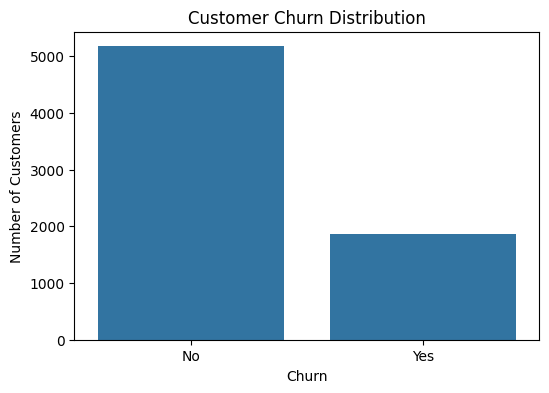

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

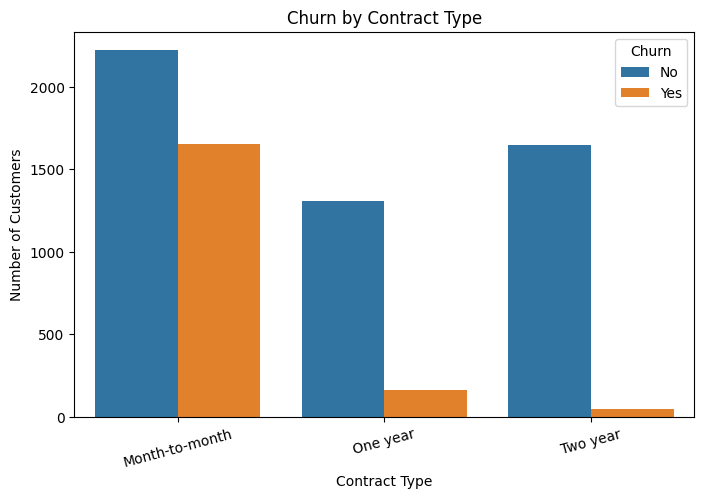

In [ ]:
##Contract Type vs Churn
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

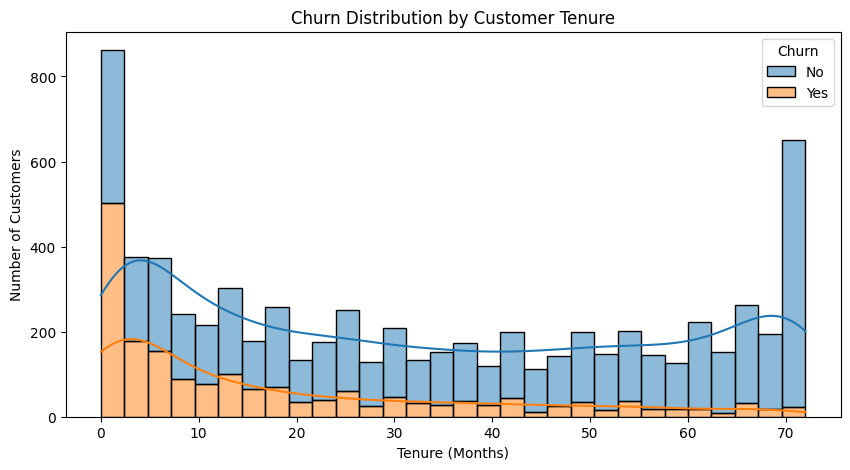

In [ ]:
##Tenure vs Churn
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Churn Distribution by Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()


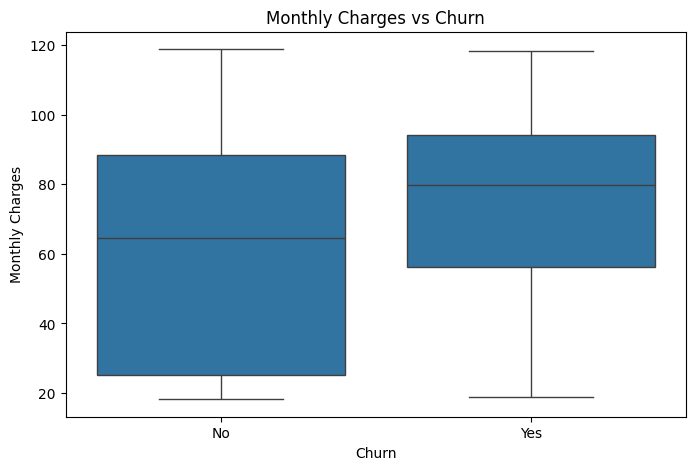

In [ ]:
##Monthly Charges vs Churn
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

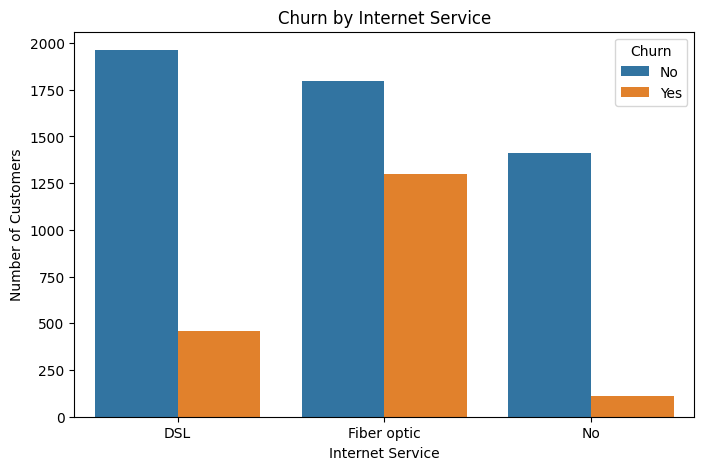

In [ ]:
##Internet Service vs Churn
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
# Churn rate by contract type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


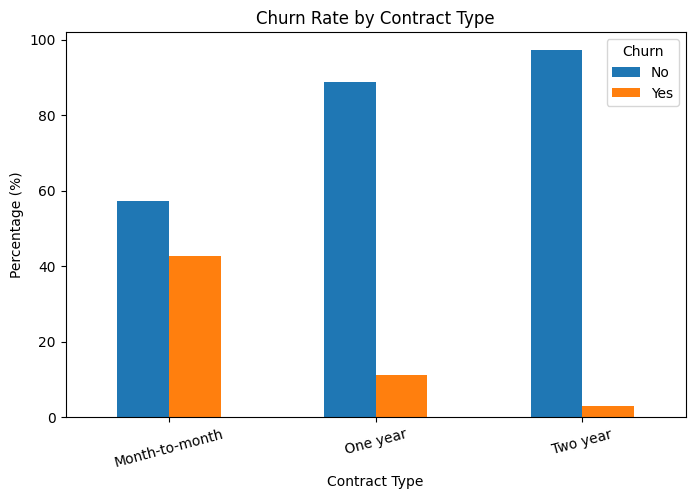

In [ ]:
contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=15)
plt.legend(title="Churn")
plt.show()

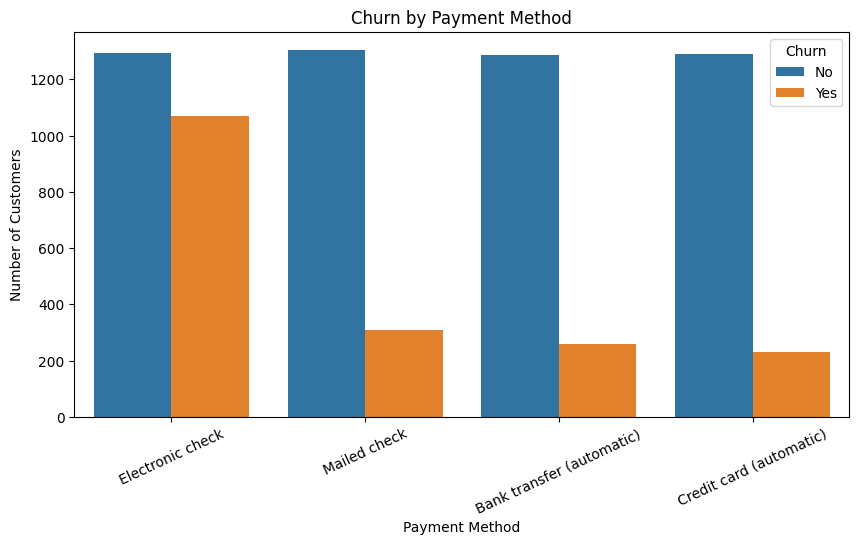

In [ ]:
##Payment Method vs Churn
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.show()

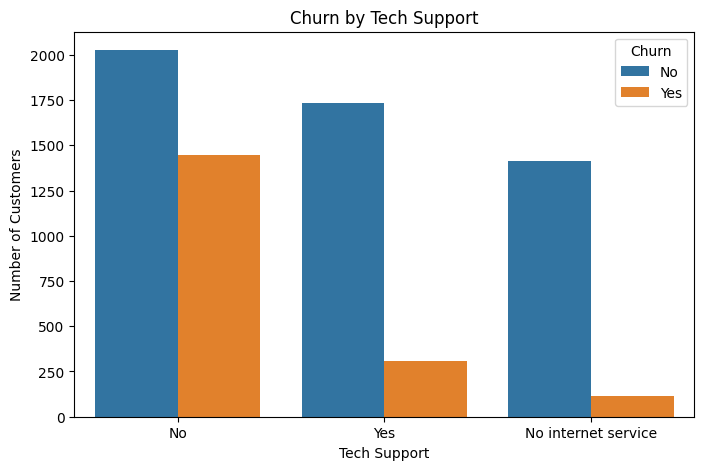

In [ ]:
##Tech Support vs Churn
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TechSupport",
    hue="Churn"
)

plt.title("Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")
plt.show()

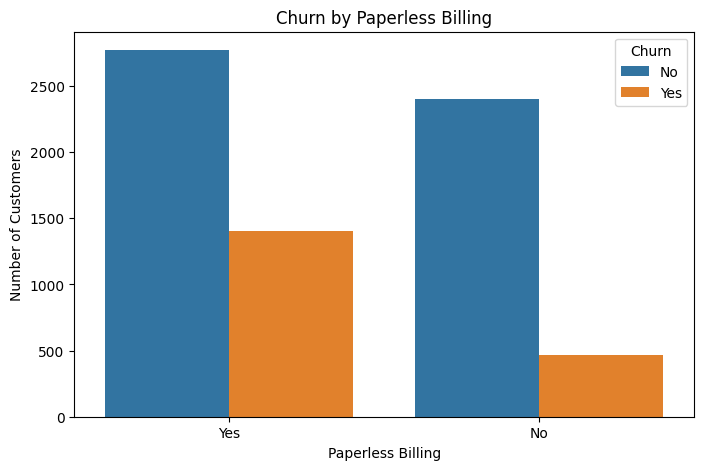

In [ ]:
#Paperless Billing vs Churn
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="PaperlessBilling",
    hue="Churn"
)

plt.title("Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
# Compare numerical features by churn

print("Average values by Churn:")
print(
    df.groupby("Churn")[["tenure", "MonthlyCharges"]]
      .mean()
)

Average values by Churn:
          tenure  MonthlyCharges
Churn                           
No     37.569965       61.265124
Yes    17.979133       74.441332


In [ ]:
# Create tenure groups

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=["0-6 months", "7-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(tenure_churn)

Churn                No        Yes
TenureGroup                       
0-6 months    46.666667  53.333333
7-12 months   64.113475  35.886525
13-24 months  71.289062  28.710938
25-48 months  79.611041  20.388959
49-72 months  90.486824   9.513176


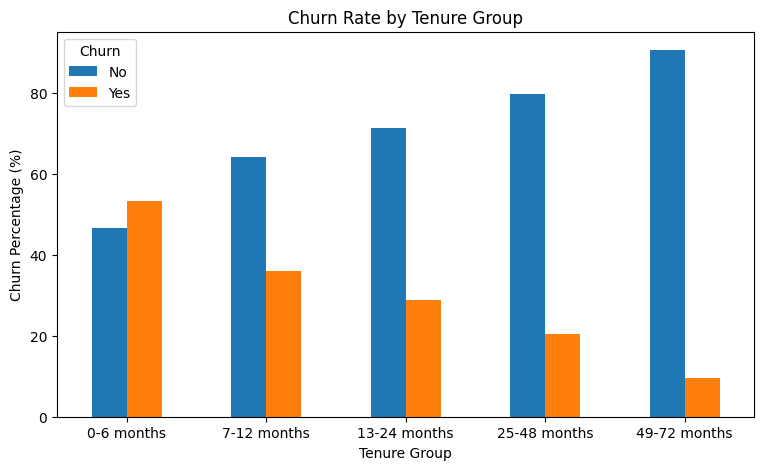

In [ ]:
tenure_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

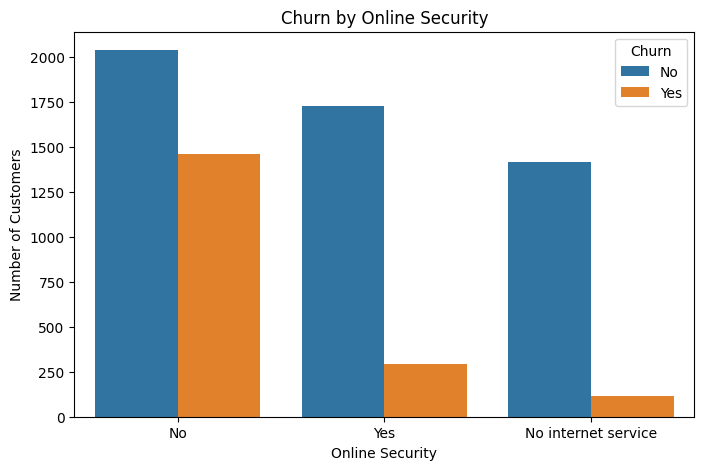

In [ ]:
#Online Security vs Churn
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OnlineSecurity",
    hue="Churn"
)

plt.title("Churn by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Display rows with missing TotalCharges
df[df["TotalCharges"].isnull()][
    ["tenure", "TotalCharges", "Churn"]
].head()

Missing TotalCharges: 11


,tenure,TotalCharges,Churn
488,0,NaN,No
753,0,NaN,No
936,0,NaN,No
1082,0,NaN,No
1340,0,NaN,No


In [ ]:
# Fill missing TotalCharges with zero
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after cleaning:", df["TotalCharges"].isnull().sum())
print("TotalCharges data type:", df["TotalCharges"].dtype)

Missing values after cleaning: 0
TotalCharges data type: float64


In [ ]:
# Save cleaned dataset for the next stage
df.to_csv("/content/churn_data_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (7043, 22)


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [ ]:
# Create features and target
X = df.drop(
    columns=["Churn", "customerID", "TenureGroup"]
)

y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining churn rate:")
print(y_train.mean())

print("\nTesting churn rate:")
print(y_test.mean())

Training rows: 5634
Testing rows: 1409

Training churn rate:
0.2653532126375577

Testing churn rate:
0.2654364797728886


In [ ]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:

# Step 21: Create preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [ ]:

# Step 22: Train a baseline model

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline Model Results")
print("----------------------")
print("Accuracy:", baseline_model.score(X_test, y_test))
print("Predicted churn customers:", baseline_predictions.sum())


Baseline Model Results
----------------------
Accuracy: 0.7345635202271115
Predicted churn customers: 0


In [ ]:

# Step 23: Train Logistic Regression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", logistic_model.score(X_test, y_test))
print("Predicted churn customers:", logistic_predictions.sum())


Logistic Regression Results
---------------------------
Accuracy: 0.7381121362668559
Predicted churn customers: 581


In [ ]:

# Step 24: Evaluate Logistic Regression

print("Logistic Regression Evaluation")
print("--------------------------------")

print("Accuracy:", logistic_model.score(X_test, y_test))

print("Precision:",
      precision_score(y_test, logistic_predictions))

print("Recall:",
      recall_score(y_test, logistic_predictions))

print("F1-Score:",
      f1_score(y_test, logistic_predictions))

print("PR-AUC:",
      average_precision_score(y_test, logistic_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    target_names=["No Churn", "Churn"]
))


Logistic Regression Evaluation
--------------------------------
Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1-Score: 0.6136125654450262
PR-AUC: 0.6326914342266071

Confusion Matrix:
[[747 288]
 [ 81 293]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [ ]:

# Step 25: Train Random Forest Model

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
random_forest_model.fit(X_train, y_train)

# Predictions
rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Random Forest Evaluation")
print("------------------------")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions))
print("Recall:", recall_score(y_test, rf_predictions))
print("F1-Score:", f1_score(y_test, rf_predictions))
print("PR-AUC:", average_precision_score(y_test, rf_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))


Random Forest Evaluation
------------------------
Accuracy: 0.7828246983676366
Precision: 0.6188811188811189
Recall: 0.4732620320855615
F1-Score: 0.5363636363636364
PR-AUC: 0.6144552287605821

Confusion Matrix:
[[926 109]
 [197 177]]


In [ ]:

!pip install -q shap gradio joblib pandas numpy scikit-learn xgboost


In [ ]:

# Step 27: Train XGBoost Model

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
xgb_model.fit(X_train, y_train)

# Predictions
xgb_predictions = xgb_model.predict(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

# Evaluation
print("XGBoost Evaluation")
print("------------------")
print("Accuracy:", accuracy_score(y_test, xgb_predictions))
print("Precision:", precision_score(y_test, xgb_predictions))
print("Recall:", recall_score(y_test, xgb_predictions))
print("F1-Score:", f1_score(y_test, xgb_predictions))
print("PR-AUC:", average_precision_score(y_test, xgb_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))


XGBoost Evaluation
------------------
Accuracy: 0.8055358410220014
Precision: 0.6724137931034483
Recall: 0.5213903743315508
F1-Score: 0.5873493975903614
PR-AUC: 0.6591734173219286

Confusion Matrix:
[[940  95]
 [179 195]]


In [ ]:

# Step 29: Stratified 5-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd

# Stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define all 4 models
models = {
    "Baseline": DummyClassifier(strategy="prior"),

    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Compare models using PR-AUC
results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Mean PR-AUC": scores["test_score"].mean(),
        "Std PR-AUC": scores["test_score"].std()
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Mean PR-AUC",
    ascending=False
).reset_index(drop=True)

print("Stratified 5-Fold CV Results")
display(results_df)


Stratified 5-Fold CV Results


,Model,Mean PR-AUC,Std PR-AUC
0,XGBoost,0.667530,0.022223
1,Logistic Regression,0.659985,0.019476
2,Random Forest,0.610133,0.030780
3,Baseline,0.265353,0.000094


In [ ]:

# Step 31: Compare XGBoost with Class Weights vs SMOTE

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model 1: XGBoost with class weights
# scale_pos_weight gives additional weight to churn cases
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

weighted_xgb = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=negative_count / positive_count,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Model 2: SMOTE applied only after preprocessing
smote_xgb = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

models = {
    "XGBoost with class weights": weighted_xgb,
    "XGBoost with SMOTE": smote_xgb
}

results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Mean PR-AUC": scores["test_score"].mean(),
        "Std PR-AUC": scores["test_score"].std()
    })

imbalance_results = pd.DataFrame(results)
print("Class Weights vs SMOTE")
display(imbalance_results)


Class Weights vs SMOTE


,Model,Mean PR-AUC,Std PR-AUC
0,XGBoost with class weights,0.668993,0.022232
1,XGBoost with SMOTE,0.662224,0.017757


In [ ]:

# Step 33: Define Business Costs

COST_OF_LOST_CUSTOMER = 200
COST_OF_RETENTION_OFFER = 20

print("Business Cost Assumptions")
print("-------------------------")
print("Cost of losing a customer: $",
      COST_OF_LOST_CUSTOMER)
print("Cost of retention offer: $",
      COST_OF_RETENTION_OFFER)


Business Cost Assumptions
-------------------------
Cost of losing a customer: $ 200
Cost of retention offer: $ 20


In [ ]:

# Step 34: Cost-Based Threshold Tuning

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

COST_OF_LOST_CUSTOMER = 200
COST_OF_RETENTION_OFFER = 20

# Training data ko training aur validation mein divide karna
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

negative_count = int((y_fit == 0).sum())
positive_count = int((y_fit == 1).sum())

# XGBoost model
cost_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=negative_count / positive_count,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Model train karna
cost_model.fit(X_fit, y_fit)

# Churn ki probability nikalna
val_probabilities = cost_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    total_cost = (
        fn * COST_OF_LOST_CUSTOMER
        + (tp + fp) * COST_OF_RETENTION_OFFER
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "False Negatives": fn,
        "Offers Sent": int(tp + fp),
        "Total Cost ($)": total_cost
    })

threshold_df = pd.DataFrame(threshold_results)

print("Threshold Cost Comparison")
display(threshold_df)

best_row = threshold_df.loc[
    threshold_df["Total Cost ($)"].idxmin()
]

best_threshold = float(best_row["Threshold"])

print("Best validation threshold:", best_threshold)
print("Estimated validation cost: $",
      int(best_row["Total Cost ($)"]))


Threshold Cost Comparison


,Threshold,False Negatives,Offers Sent,Total Cost ($)
0,0.10,5,817,17340
1,0.15,10,766,17320
2,0.20,16,708,17360
3,0.25,28,648,18560
4,0.30,33,593,18460
5,0.35,41,553,19260
6,0.40,50,511,20220
7,0.45,61,472,21640
8,0.50,67,435,22100
9,0.55,75,402,23040


Best validation threshold: 0.15
Estimated validation cost: $ 17320


In [ ]:

# Step 35: Probability Calibration

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    brier_score_loss,
    log_loss
)

# Calibrate the existing cost model
calibrated_model = CalibratedClassifierCV(
    estimator=cost_model,
    method="sigmoid",
    cv=3
)

calibrated_model.fit(X_fit, y_fit)

# Get calibrated probabilities
calibrated_probabilities = calibrated_model.predict_proba(X_val)[:, 1]

print("Probability Calibration Results")
print("--------------------------------")
print(
    "Brier Score:",
    round(brier_score_loss(y_val, calibrated_probabilities), 4)
)
print(
    "Log Loss:",
    round(log_loss(y_val, calibrated_probabilities), 4)
)

print("\nFirst 10 calibrated churn probabilities:")
print(calibrated_probabilities[:10])


Probability Calibration Results
--------------------------------
Brier Score: 0.1338
Log Loss: 0.417

First 10 calibrated churn probabilities:
[0.2426606  0.05510222 0.0476987  0.07741769 0.21804661 0.05796825
 0.19085834 0.04467151 0.04119072 0.15422773]


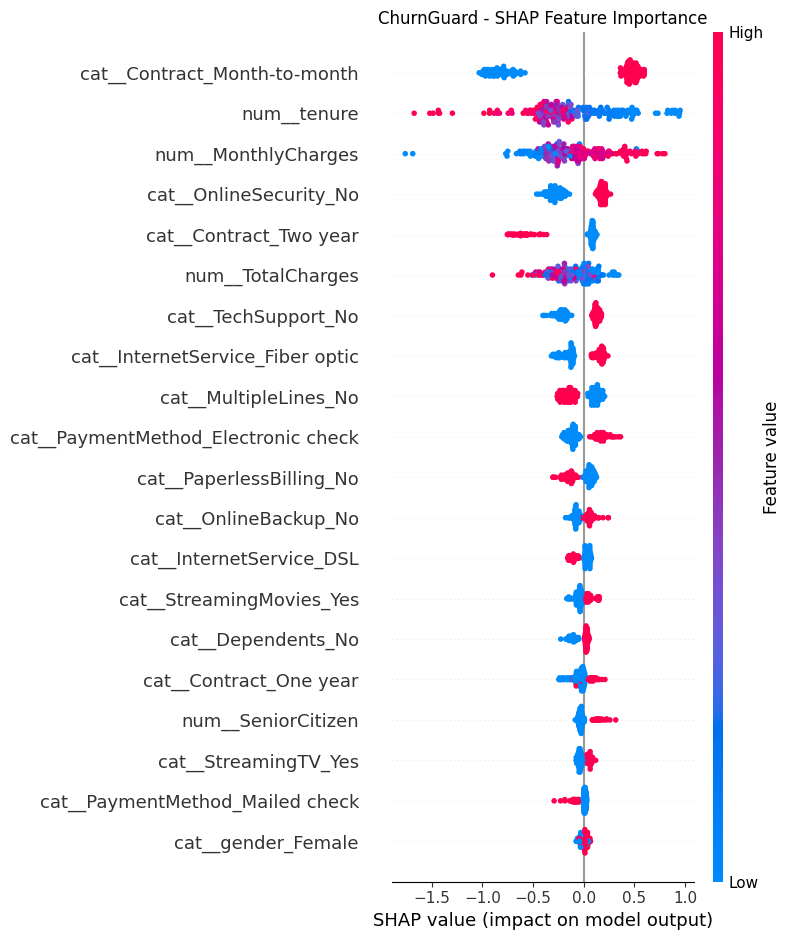

In [ ]:

# Step 36: SHAP Explainability

import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get the trained XGBoost model from the pipeline
xgb_model = cost_model.named_steps["classifier"]

# Transform validation data using the fitted preprocessor
X_val_transformed = cost_model.named_steps[
    "preprocessor"
].transform(X_val)

# Get transformed feature names
feature_names = cost_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create a sample for faster SHAP calculation
sample_size = min(200, X_val_transformed.shape[0])

X_shap = X_val_transformed[:sample_size]

# Explain the model predictions
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

# Summary plot
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    show=False
)

plt.title("ChurnGuard - SHAP Feature Importance")
plt.tight_layout()
plt.show()


In [ ]:

# Step 37: Top 3 Important Churn Features

mean_shap = np.abs(shap_values).mean(axis=0)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean SHAP Importance": mean_shap
})

feature_importance = feature_importance.sort_values(
    by="Mean SHAP Importance",
    ascending=False
)

print("Top 10 Important Churn Features:")
display(feature_importance.head(10))

print("\nTop 3 Churn Reasons:")
display(feature_importance.head(3))


Top 10 Important Churn Features:


,Feature,Mean SHAP Importance
36,cat__Contract_Month-to-month,0.627270
1,num__tenure,0.383971
2,num__MonthlyCharges,0.303088
18,cat__OnlineSecurity_No,0.230571
38,cat__Contract_Two year,0.202487
3,num__TotalCharges,0.180006
27,cat__TechSupport_No,0.174480
16,cat__InternetService_Fiber optic,0.161623
12,cat__MultipleLines_No,0.138818
43,cat__PaymentMethod_Electronic check,0.135824



Top 3 Churn Reasons:


,Feature,Mean SHAP Importance
36,cat__Contract_Month-to-month,0.627270
1,num__tenure,0.383971
2,num__MonthlyCharges,0.303088


In [ ]:
# Step 38: Create ChurnGuard Gradio App (Fixed)

import gradio as gr
import pandas as pd
import numpy as np

def predict_churn(
    gender, senior_citizen, partner, dependents,
    tenure, phone_service, internet_service,
    online_security, tech_support, contract,
    paperless_billing, payment_method,
    monthly_charges, total_charges
):
    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": int(senior_citizen),
        "Partner": partner,
        "Dependents": dependents,
        "tenure": int(tenure),
        "PhoneService": phone_service,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "TechSupport": tech_support,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": float(monthly_charges),
        "TotalCharges": float(total_charges),
        "MultipleLines": "No",
        "OnlineBackup": "No",
        "DeviceProtection": "No",
        "StreamingTV": "No",
        "StreamingMovies": "No"
    }])

    # Ensure column order matches the training dataset
    feature_cols = [
        'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
        'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
        'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
        'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
        'MonthlyCharges', 'TotalCharges'
    ]
    customer = customer[feature_cols]

    probability = calibrated_model.predict_proba(customer)[0, 1]

    if probability >= best_threshold:
        risk = "High Risk - Action Required"
    elif probability >= 0.10:
        risk = "Medium Risk - Review Options"
    else:
        risk = "Low Risk - Stable Customer"

    prob_percentage = f"{round(float(probability) * 100, 2)}%"

    # Return two separate values for the two textbox outputs
    return prob_percentage, risk

demo = gr.Interface(
    fn=predict_churn,
    inputs=[
        gr.Dropdown(["Female", "Male"], value="Female", label="Gender"),
        gr.Radio([0, 1], value=0, label="Senior Citizen"),
        gr.Radio(["Yes", "No"], value="No", label="Partner"),
        gr.Radio(["Yes", "No"], value="No", label="Dependents"),
        gr.Slider(0, 72, value=12, step=1, label="Tenure (months)"),
        gr.Radio(["Yes", "No"], value="Yes", label="Phone Service"),
        gr.Dropdown(
            ["DSL", "Fiber optic", "No"],
            value="Fiber optic",
            label="Internet Service"
        ),
        gr.Dropdown(["Yes", "No", "No internet service"], value="No", label="Online Security"),
        gr.Dropdown(["Yes", "No", "No internet service"], value="No", label="Tech Support"),
        gr.Dropdown(
            ["Month-to-month", "One year", "Two year"],
            value="Month-to-month",
            label="Contract"
        ),
        gr.Radio(["Yes", "No"], value="Yes", label="Paperless Billing"),
        gr.Dropdown(
            ["Electronic check", "Mailed check",
             "Bank transfer (automatic)", "Credit card (automatic)"],
            value="Electronic check",
            label="Payment Method"
        ),
        gr.Number(value=70.0, label="Monthly Charges"),
        gr.Number(value=840.0, label="Total Charges")
    ],
    outputs=[
        gr.Textbox(label="Churn Probability"),
        gr.Textbox(label="Risk Level")
    ],
    title="ChurnGuard - Customer Churn Prediction",
    description="Enter customer details below to estimate churn risk and view recommendations."
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://5e629b3aa2bb9b81e1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://5e629b3aa2bb9b81e1.gradio.live


In [ ]:

import os
import pandas as pd
import numpy as np

print("Current folder:", os.getcwd())
print("\nCSV files:", [f for f in os.listdir() if f.endswith(".csv")])
print("\nSaved model files:", [
    f for f in os.listdir()
    if f.endswith((".pkl", ".joblib"))
])

Current folder: /content

CSV files: ['churn_data_cleaned.csv', 'customer_churn_data.csv']

Saved model files: []


In [ ]:
##Model file search

import os

for folder in ["/content", "/content/drive/MyDrive"]:
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            dirs[:] = [
                d for d in dirs
                if d not in [".cache", ".config", "site-packages"]
            ]
            for file in files:
                if file.endswith((".joblib", ".pkl")):
                    print(os.path.join(root, file))


In [ ]:

print("artifact exists:", "artifact" in globals())
print("model exists:", "model" in globals())
print("cost_model exists:", "cost_model" in globals())


artifact exists: False
model exists: True
cost_model exists: True


In [ ]:

import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir("/content"))


Current folder: /content
Files available: ['.config', '.gradio', 'churn_data_cleaned.csv', 'customer_churn_data.csv', '.ipynb_checkpoints', 'sample_data']


In [ ]:

import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".config", ".ipynb_checkpoints", ".gradio"]]
    for file in files:
        if file.endswith((".pkl", ".joblib", ".json")):
            print(os.path.join(root, file))


/content/sample_data/anscombe.json


In [ ]:

print("model available:", "model" in globals())
print("cost_model available:", "cost_model" in globals())
print("preprocessor available:", "preprocessor" in globals())
print("X_train available:", "X_train" in globals())
print("X_test available:", "X_test" in globals())


model available: True
cost_model available: True
preprocessor available: True
X_train available: True
X_test available: True


In [ ]:

import os
import joblib

os.makedirs("/content/artifacts", exist_ok=True)

joblib.dump(model, "/content/artifacts/churn_model.pkl")
joblib.dump(cost_model, "/content/artifacts/cost_model.pkl")
joblib.dump(preprocessor, "/content/artifacts/preprocessor.pkl")

print("Model files saved successfully!")
print("Files:", os.listdir("/content/artifacts"))


Model files saved successfully!
Files: ['cost_model.pkl', 'churn_model.pkl', 'preprocessor.pkl']


In [ ]:

import os

for file in [
    "/content/artifacts/churn_model.pkl",
    "/content/artifacts/cost_model.pkl",
    "/content/artifacts/preprocessor.pkl"
]:
    print(os.path.basename(file), "exists:", os.path.exists(file))


churn_model.pkl exists: True
cost_model.pkl exists: True
preprocessor.pkl exists: True


In [ ]:

required_vars = [
    "cost_model", "X_fit", "X_val",
    "y_fit", "y_val"
]

for name in required_vars:
    print(name, "available" if name in globals() else "MISSING")

cost_model available
X_fit available
X_val available
y_fit available
y_val available


In [ ]:

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    brier_score_loss, log_loss, confusion_matrix,
    precision_score, recall_score, f1_score
)
import numpy as np
import pandas as pd

# 1. Calibrate the model using training data only
calibrated_model = CalibratedClassifierCV(
    estimator=cost_model,
    method="sigmoid",
    cv=3
)

calibrated_model.fit(X_fit, y_fit)

# 2. Get calibrated validation probabilities
calibrated_probabilities = calibrated_model.predict_proba(X_val)[:, 1]

print("CALIBRATION RESULTS")
print("-------------------")
print("Brier Score:",
      round(brier_score_loss(y_val, calibrated_probabilities), 4))
print("Log Loss:",
      round(log_loss(y_val, calibrated_probabilities), 4))

# 3. Tune threshold on validation data
COST_OF_LOST_CUSTOMER = 200
COST_OF_RETENTION_OFFER = 20
RETENTION_SUCCESS_RATE = 0.30

results = []

for threshold in np.arange(0.05, 0.96, 0.05):
    pred = (calibrated_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred, labels=[0, 1]
    ).ravel()

    offers = tp + fp

    expected_cost = (
        offers * COST_OF_RETENTION_OFFER
        + (fn + tp * (1 - RETENTION_SUCCESS_RATE))
        * COST_OF_LOST_CUSTOMER
    )

    results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "F1": f1_score(y_val, pred, zero_division=0),
        "Offers": int(offers),
        "Expected Cost": float(expected_cost)
    })

threshold_df = pd.DataFrame(results)
display(threshold_df)

# 4. Select threshold with minimum expected cost
best_threshold = float(
    threshold_df.loc[
        threshold_df["Expected Cost"].idxmin(),
        "Threshold"
    ]
)

print("\nSelected threshold:", best_threshold)
print("Retention success assumption:", RETENTION_SUCCESS_RATE)

CALIBRATION RESULTS
-------------------
Brier Score: 0.1338
Log Loss: 0.417


,Threshold,Precision,Recall,F1,Offers,Expected Cost
0,0.05,0.339061,0.989967,0.505119,873,59500.0
1,0.10,0.401471,0.913043,0.557712,680,57020.0
2,0.15,0.452007,0.866221,0.594037,573,55720.0
3,0.20,0.490196,0.836120,0.618047,510,55000.0
4,0.25,0.509804,0.782609,0.617414,459,54940.0
5,0.30,0.551220,0.755853,0.637518,410,54440.0
6,0.35,0.588076,0.725753,0.649701,369,54160.0
7,0.40,0.628834,0.685619,0.656000,326,54020.0
8,0.45,0.670290,0.618729,0.643478,276,54220.0
9,0.50,0.686695,0.535117,0.601504,233,54860.0



Selected threshold: 0.4
Retention success assumption: 0.3


CHURNGUARD - FINAL TEST RESULTS
--------------------------------
Threshold: 0.4
Accuracy: 0.7828
Precision: 0.5787
Recall: 0.6684
F1-Score: 0.6203
PR-AUC: 0.6575
Brier Score: 0.1368

Confusion Matrix:
[[853 182]
 [124 250]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.82      0.85      1035
       Churn       0.58      0.67      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.73      1409
weighted avg       0.79      0.78      0.79      1409



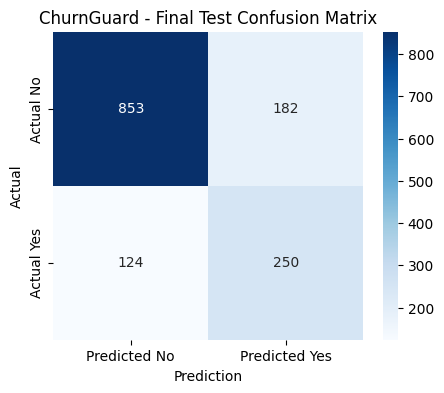

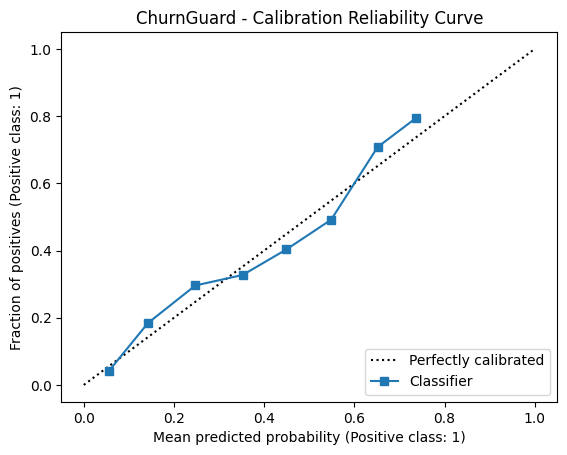

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

# Step 3A: Final test predictions
test_probabilities = calibrated_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

# Step 3B: Final metrics
print("CHURNGUARD - FINAL TEST RESULTS")
print("--------------------------------")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, test_predictions, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_probabilities), 4))
print("Brier Score:", round(brier_score_loss(y_test, test_probabilities), 4))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Step 3C: Plot confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
plt.title("ChurnGuard - Final Test Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()

# Step 3D: Calibration reliability curve on the test set
CalibrationDisplay.from_predictions(
    y_test,
    test_probabilities,
    n_bins=10,
    strategy="uniform"
)
plt.title("ChurnGuard - Calibration Reliability Curve")
plt.show()

CHURNGUARD - FINAL TEST RESULTS
--------------------------------
Threshold: 0.4
Accuracy: 0.7828
Precision: 0.5787
Recall: 0.6684
F1-Score: 0.6203
PR-AUC: 0.6575
Brier Score: 0.1368

Confusion Matrix:
 [[853 182]
 [124 250]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.82      0.85      1035
       Churn       0.58      0.67      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.73      1409
weighted avg       0.79      0.78      0.79      1409



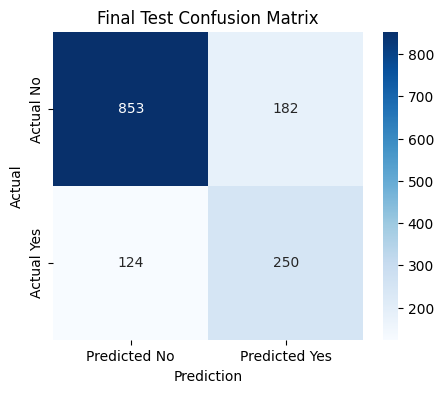

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score,
    confusion_matrix, classification_report,
    brier_score_loss
)
import matplotlib.pyplot as plt
import seaborn as sns

# Final predictions on test data
test_probabilities = calibrated_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

print("CHURNGUARD - FINAL TEST RESULTS")
print("--------------------------------")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, test_predictions, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_probabilities), 4))
print("Brier Score:", round(brier_score_loss(y_test, test_probabilities), 4))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
print("\nConfusion Matrix:\n", cm)

print("\nClassification Report:")
print(classification_report(
    y_test, test_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.title("Final Test Confusion Matrix")
plt.show()

In [ ]:

print("Model available:", "calibrated_model" in globals())
print("Threshold available:", "best_threshold" in globals())
print("Test data available:", "X_test" in globals() and "y_test" in globals())

Model available: True
Threshold available: True
Test data available: True


CHURNGUARD - FINAL TEST RESULTS
--------------------------------
Threshold: 0.4
Accuracy: 0.7828
Precision: 0.5787
Recall: 0.6684
F1-Score: 0.6203
PR-AUC: 0.6575
Brier Score: 0.1368

Confusion Matrix:
[[853 182]
 [124 250]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.82      0.85      1035
       Churn       0.58      0.67      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.73      1409
weighted avg       0.79      0.78      0.79      1409



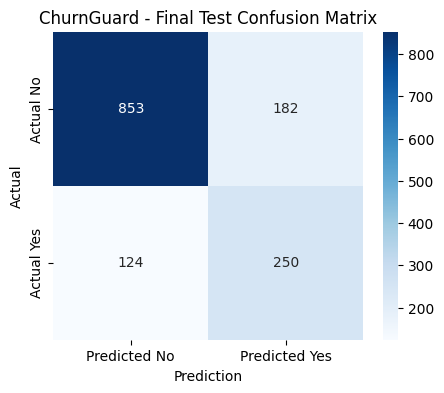

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score,
    confusion_matrix, classification_report,
    brier_score_loss
)
import matplotlib.pyplot as plt
import seaborn as sns

# Predict on the untouched test set
test_probabilities = calibrated_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

print("CHURNGUARD - FINAL TEST RESULTS")
print("--------------------------------")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, test_predictions, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_probabilities), 4))
print("Brier Score:", round(brier_score_loss(y_test, test_probabilities), 4))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test, test_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
plt.title("ChurnGuard - Final Test Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()

In [ ]:

import joblib
import os

# Save the trained model and settings together
artifact = {
    "model": calibrated_model,
    "threshold": best_threshold,
    "feature_columns": X.columns.tolist(),
    "retention_success_rate": RETENTION_SUCCESS_RATE,
    "cost_of_lost_customer": COST_OF_LOST_CUSTOMER,
    "cost_of_retention_offer": COST_OF_RETENTION_OFFER
}

model_path = "/content/churnguard_model.joblib"
joblib.dump(artifact, model_path)

# Verify that the file was saved
print("Model saved:", os.path.exists(model_path))
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")

# Test loading the saved model
loaded_artifact = joblib.load(model_path)

print("Loaded threshold:", loaded_artifact["threshold"])
print("Number of features:", len(loaded_artifact["feature_columns"]))
print("Model loaded successfully!")

Model saved: True
File size: 1290.12 KB
Loaded threshold: 0.4
Number of features: 19
Model loaded successfully!


In [ ]:

from google.colab import files

files.download("/content/churnguard_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip install -q gradio joblib shap

In [ ]:

import joblib
import os

model_path = "/content/churnguard_model.joblib"

artifact = joblib.load(model_path)

model = artifact["model"]
threshold = artifact["threshold"]

print("ChurnGuard model loaded successfully!")
print("Prediction threshold:", threshold)
print("Expected input features:", len(artifact["feature_columns"]))

ChurnGuard model loaded successfully!
Prediction threshold: 0.4
Expected input features: 19


In [ ]:

import gradio as gr
import pandas as pd
import numpy as np

feature_columns = artifact["feature_columns"]

print("Total input features:", len(feature_columns))
print("Features required by model:")
for feature in feature_columns:
    print("-", feature)

Total input features: 19
Features required by model:
- gender
- SeniorCitizen
- Partner
- Dependents
- tenure
- PhoneService
- MultipleLines
- InternetService
- OnlineSecurity
- OnlineBackup
- DeviceProtection
- TechSupport
- StreamingTV
- StreamingMovies
- Contract
- PaperlessBilling
- PaymentMethod
- MonthlyCharges
- TotalCharges


In [ ]:

def predict_churn(
    gender, senior_citizen, partner, dependents, tenure,
    phone_service, multiple_lines, internet_service,
    online_security, online_backup, device_protection,
    tech_support, streaming_tv, streaming_movies,
    contract, paperless_billing, payment_method,
    monthly_charges, total_charges
):
    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": int(senior_citizen == "Yes"),
        "Partner": partner,
        "Dependents": dependents,
        "tenure": int(tenure),
        "PhoneService": phone_service,
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": float(monthly_charges),
        "TotalCharges": float(total_charges)
    }], columns=feature_columns)

    probability = float(model.predict_proba(customer)[0, 1])
    prediction = int(probability >= threshold)

    if probability >= 0.60:
        risk = "High"
        recommendation = "Contact the customer promptly and offer a suitable retention plan."
    elif probability >= threshold:
        risk = "Medium"
        recommendation = "Review customer concerns and consider a targeted retention offer."
    else:
        risk = "Low"
        recommendation = "Maintain service quality and monitor customer satisfaction."

    return (
        "Likely to Churn" if prediction else "Likely to Stay",
        f"{probability:.1%}",
        risk,
        recommendation
    )

print("Prediction function created successfully!")

Prediction function created successfully!


In [ ]:

with gr.Blocks(title="ChurnGuard - Customer Churn Prediction") as demo:
    gr.Markdown("# ChurnGuard")
    gr.Markdown("### Customer Churn Prediction & Retention Tool")
    gr.Markdown("Customer details enter karein aur churn risk check karein.")

    with gr.Row():
        gender = gr.Dropdown(["Female", "Male"], label="Gender", value="Female")
        senior_citizen = gr.Radio(["No", "Yes"], label="Senior Citizen", value="No")
        partner = gr.Radio(["No", "Yes"], label="Partner", value="Yes")
        dependents = gr.Radio(["No", "Yes"], label="Dependents", value="No")

    with gr.Row():
        tenure = gr.Slider(0, 72, value=12, step=1, label="Tenure (months)")
        phone_service = gr.Radio(["No", "Yes"], label="Phone Service", value="Yes")
        multiple_lines = gr.Dropdown(
            ["No phone service", "No", "Yes"],
            label="Multiple Lines", value="No"
        )

    with gr.Row():
        internet_service = gr.Dropdown(
            ["DSL", "Fiber optic", "No"], label="Internet Service", value="Fiber optic"
        )
        online_security = gr.Dropdown(
            ["No", "Yes", "No internet service"],
            label="Online Security", value="No"
        )
        online_backup = gr.Dropdown(
            ["No", "Yes", "No internet service"],
            label="Online Backup", value="No"
        )

    with gr.Row():
        device_protection = gr.Dropdown(
            ["No", "Yes", "No internet service"],
            label="Device Protection", value="No"
        )
        tech_support = gr.Dropdown(
            ["No", "Yes", "No internet service"],
            label="Tech Support", value="No"
        )
        streaming_tv = gr.Dropdown(
            ["No", "Yes", "No internet service"],
            label="Streaming TV", value="No"
        )
        streaming_movies = gr.Dropdown(
            ["No", "Yes", "No internet service"],
            label="Streaming Movies", value="No"
        )

    with gr.Row():
        contract = gr.Dropdown(
            ["Month-to-month", "One year", "Two year"],
            label="Contract", value="Month-to-month"
        )
        paperless_billing = gr.Radio(
            ["No", "Yes"], label="Paperless Billing", value="Yes"
        )
        payment_method = gr.Dropdown(
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ],
            label="Payment Method", value="Electronic check"
        )

    with gr.Row():
        monthly_charges = gr.Number(
            label="Monthly Charges ($)", value=70.0, minimum=0
        )
        total_charges = gr.Number(
            label="Total Charges ($)", value=840.0, minimum=0
        )

    submit_btn = gr.Button("Predict Churn", variant="primary")

    prediction_output = gr.Textbox(label="Prediction")
    probability_output = gr.Textbox(label="Churn Probability")
    risk_output = gr.Textbox(label="Risk Level")
    recommendation_output = gr.Textbox(label="Retention Recommendation")

    submit_btn.click(
        fn=predict_churn,
        inputs=[
            gender, senior_citizen, partner, dependents, tenure,
            phone_service, multiple_lines, internet_service,
            online_security, online_backup, device_protection,
            tech_support, streaming_tv, streaming_movies,
            contract, paperless_billing, payment_method,
            monthly_charges, total_charges
        ],
        outputs=[
            prediction_output, probability_output,
            risk_output, recommendation_output
        ]
    )

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [ ]:

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://980114b6a0c1a1ade8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# Check that the required app variables exist
required_vars = [
    "demo",
    "model",
    "calibrated_model",
    "best_threshold",
    "artifact",
    "feature_columns"
]

for name in required_vars:
    print(name, "OK" if name in globals() else "MISSING")

# Launch the current Gradio app
demo.launch(share=True, debug=True)


demo OK
model OK
calibrated_model OK
best_threshold OK
artifact MISSING
feature_columns MISSING
Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://5e629b3aa2bb9b81e1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# missing variables


import joblib

# Restore feature columns
if "feature_columns" not in globals():
    if "X" in globals():
        feature_columns = X.columns.tolist()
    else:
        print("The X variable is missing. Please rerun the dataset and model cells.")

# Restore the model artifact
if "feature_columns" in globals():
    artifact = {
        "model": calibrated_model,
        "threshold": best_threshold,
        "feature_columns": feature_columns,
        "retention_success_rate": globals().get("RETENTION_SUCCESS_RATE", 0.30),
        "cost_of_lost_customer": globals().get("COST_OF_LOST_CUSTOMER", 200),
        "cost_of_retention_offer": globals().get("COST_OF_RETENTION_OFFER", 20)
    }

    # Save the model artifact
    joblib.dump(artifact, "/content/churnguard_model.joblib")

    print("Artifact:", "OK")
    print("Feature columns:", "OK")
    print("Number of features:", len(feature_columns))
    print("Model artifact saved successfully!")



The X variable is missing. Please rerun the dataset and model cells.


In [ ]:

import os

print("Current folder files:")
print(os.listdir("/content"))

print("\nCSV files found:")
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


Current folder files:
['.config', 'sample_data']

CSV files found:
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving customer_churn_data.csv to customer_churn_data.csv


In [ ]:

import pandas as pd

# Load uploaded dataset
df = pd.read_csv("/content/customer_churn_data.csv")

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
).fillna(0)

# Recreate the 19 model features
feature_columns = [
    col for col in df.columns
    if col not in ["Churn", "customerID", "TenureGroup"]
]

X = df[feature_columns].copy()
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("X shape:", X.shape)
print("Number of features:", len(feature_columns))
print("Target values:")
print(y.value_counts())


Dataset loaded successfully!
Dataset shape: (7043, 21)
X shape: (7043, 19)
Number of features: 19
Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:

import os

print("Checking saved model files...")

for root, dirs, files_list in os.walk("/content"):
    for file in files_list:
        if file.endswith((".joblib", ".pkl")):
            print(os.path.join(root, file))

print("\nChecking model variables...")

for name in [
    "model",
    "calibrated_model",
    "cost_model",
    "best_threshold",
    "threshold",
    "feature_columns",
    "explainer"
]:
    print(name, "=", "Available" if name in globals() else "Missing")


Checking saved model files...

Checking model variables...
model = Missing
calibrated_model = Missing
cost_model = Missing
best_threshold = Missing
threshold = Missing
feature_columns = Available
explainer = Missing


In [ ]:

%pip install -q scikit-learn xgboost shap imbalanced-learn gradio joblib


In [ ]:

import pandas as pd
import numpy as np
import joblib
import shap
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# Step 6: Prepare data and train ChurnGuard model

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

# Reload original dataset
df = pd.read_csv("/content/customer_churn_data.csv")

# Clean numeric TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
).fillna(0)

# Features and target
feature_columns = [
    col for col in df.columns
    if col not in ["Churn", "customerID", "TenureGroup"]
]

X = df[feature_columns].copy()
y = df["Churn"].map({"No": 0, "Yes": 1})

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

# Preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Handle class imbalance with scale_pos_weight
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Build model pipeline
cost_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train calibrated model
calibrated_model = CalibratedClassifierCV(
    estimator=cost_model,
    method="sigmoid",
    cv=3
)

calibrated_model.fit(X_train, y_train)

# Use threshold 0.40 as the starting business threshold
best_threshold = 0.40
threshold = best_threshold
model = calibrated_model

print("ChurnGuard model trained successfully!")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", len(feature_columns))
print("Threshold:", best_threshold)


ChurnGuard model trained successfully!
Training rows: 5634
Testing rows: 1409
Features: 19
Threshold: 0.4


In [ ]:

print("X available:", "X" in globals())
print("Dataset available:", "df" in globals())
print("Model available:", "calibrated_model" in globals())
print("Threshold available:", "best_threshold" in globals())
print("Feature columns available:", "feature_columns" in globals())

if "X" in globals():
    print("X shape:", X.shape)

if "feature_columns" in globals():
    print("Number of features:", len(feature_columns))


X available: True
Dataset available: True
Model available: True
Threshold available: True
Feature columns available: True
X shape: (7043, 19)
Number of features: 19


In [ ]:

print("Model available:", "model" in globals())
print("Threshold:", threshold if "threshold" in globals() else "Not set")
print("X_val available:", "X_val" in globals())
print("y_val available:", "y_val" in globals())


Model available: True
Threshold: 0.4
X_val available: False
y_val available: False


In [ ]:

from sklearn.model_selection import train_test_split

# Existing dataset se features aur target
X = df.drop(columns=["Churn", "customerID", "TenureGroup"], errors="ignore")
y = df["Churn"].map({"No": 0, "Yes": 1})

# 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Validation data ready!")


Training rows: 5634
Validation rows: 1409
Validation data ready!


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score

# Assumed business costs (example values)
COST_OF_LOST_CUSTOMER = 5000
COST_OF_RETENTION_OFFER = 500

# Predict churn probabilities on validation data
probabilities = model.predict_proba(X_val)[:, 1]

# Compare different thresholds
results = []

for t in np.arange(0.10, 0.81, 0.05):
    predictions = (probabilities >= t).astype(int)

    # False negatives = customers who churn but were not identified
    fn = int(((y_val == 1) & (predictions == 0)).sum())

    # Customers targeted with a retention offer
    targeted = int((predictions == 1).sum())

    estimated_cost = (
        fn * COST_OF_LOST_CUSTOMER
        + targeted * COST_OF_RETENTION_OFFER
    )

    results.append({
        "Threshold": round(float(t), 2),
        "Precision": round(precision_score(y_val, predictions, zero_division=0), 3),
        "Recall": round(recall_score(y_val, predictions, zero_division=0), 3),
        "Customers_Targeted": targeted,
        "Missed_Churners": fn,
        "Estimated_Cost": estimated_cost
    })

results_df = pd.DataFrame(results)
display(results_df)

best_row = results_df.loc[results_df["Estimated_Cost"].idxmin()]
print("\nLowest estimated cost threshold:", best_row["Threshold"])
print("Estimated cost:", best_row["Estimated_Cost"])


,Threshold,Precision,Recall,Customers_Targeted,Missed_Churners,Estimated_Cost
0,0.10,0.421,0.922,820,29,555000
1,0.15,0.467,0.877,702,46,581000
2,0.20,0.492,0.837,636,61,623000
3,0.25,0.518,0.802,579,74,659500
4,0.30,0.534,0.759,532,90,716000
5,0.35,0.552,0.719,487,105,768500
6,0.40,0.571,0.676,443,121,826500
7,0.45,0.596,0.615,386,144,913000
8,0.50,0.645,0.564,327,163,978500
9,0.55,0.692,0.505,273,185,1061500



Lowest estimated cost threshold: 0.1
Estimated cost: 555000.0


In [ ]:

# Set threshold selected by the cost comparison
threshold = 0.10

print("Updated threshold:", threshold)


Updated threshold: 0.1


Brier Score: 0.1367
Log Loss: 0.4218


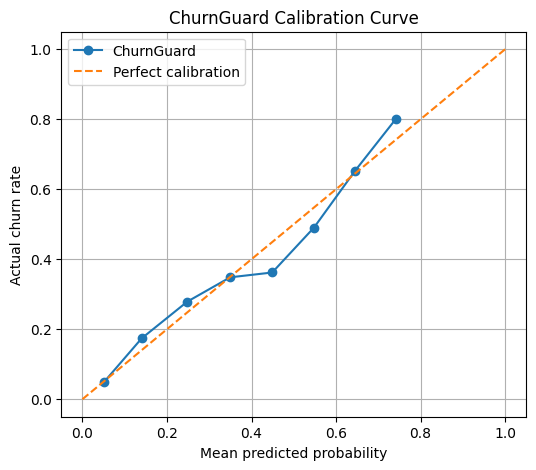

In [ ]:

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss
import numpy as np
import matplotlib.pyplot as plt

# Model ki predicted probabilities
val_probs = model.predict_proba(X_val)[:, 1]
val_probs = np.clip(val_probs, 1e-7, 1 - 1e-7)

# Calibration metrics
brier = brier_score_loss(y_val, val_probs)
ll = log_loss(y_val, val_probs)

print("Brier Score:", round(brier, 4))
print("Log Loss:", round(ll, 4))

# Calibration plot
actual_rate, predicted_rate = calibration_curve(
    y_val, val_probs, n_bins=10, strategy="uniform"
)

plt.figure(figsize=(6, 5))
plt.plot(predicted_rate, actual_rate, marker="o", label="ChurnGuard")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Actual churn rate")
plt.title("ChurnGuard Calibration Curve")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

print("Model type:", type(model).__name__)

print(
    "Is model calibrated?",
    "CalibratedClassifierCV" in type(model).__name__
)


Model type: CalibratedClassifierCV
Is model calibrated? True


In [ ]:

try:
    import shap
    print("SHAP version:", shap.__version__)
    print("SHAP is ready!")
except ImportError:
    print("SHAP is not installed.")


SHAP version: 0.52.0
SHAP is ready!


In [ ]:

print("Model type:", type(model).__name__)

print("Calibrated classifiers available:",
      len(model.calibrated_classifiers_))

# Pehle calibrated model ke andar fitted pipeline
fitted_pipeline = model.calibrated_classifiers_[0].estimator

print("Pipeline steps:", fitted_pipeline.named_steps.keys())


Model type: CalibratedClassifierCV
Calibrated classifiers available: 3
Pipeline steps: dict_keys(['preprocessor', 'classifier'])


In [ ]:

import shap
import numpy as np
import pandas as pd

# Calibrated model ke andar fitted pipeline
fitted_pipeline = model.calibrated_classifiers_[0].estimator

# Pipeline se preprocessor aur XGBoost classifier
preprocessor = fitted_pipeline.named_steps["preprocessor"]
xgb_model = fitted_pipeline.named_steps["classifier"]

print("Classifier:", type(xgb_model).__name__)

# Validation set ka pehla customer
one_customer = X_val.iloc[[0]]

# Customer ko model ke required format mein convert karna
transformed_customer = preprocessor.transform(one_customer)

# Feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# SHAP explanation
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(transformed_customer)

# Pehle customer ke SHAP values
customer_shap = np.asarray(shap_values).reshape(-1)

# Top 3 features by absolute SHAP contribution
top_indices = np.argsort(np.abs(customer_shap))[-3:][::-1]

print("\nTop 3 SHAP reasons for this customer:")

for idx in top_indices:
    direction = "pushes toward churn" if customer_shap[idx] > 0 else "pushes away from churn"
    print(
        f"{feature_names[idx]}: "
        f"SHAP={customer_shap[idx]:.4f} ({direction})"
    )


Classifier: XGBClassifier

Top 3 SHAP reasons for this customer:
num__tenure: SHAP=-1.5006 (pushes away from churn)
cat__Contract_Month-to-month: SHAP=-1.0284 (pushes away from churn)
cat__Contract_Two year: SHAP=-0.6100 (pushes away from churn)


In [ ]:

print("Gradio app available:", "demo" in globals())
print("Prediction function available:", "predict_churn" in globals())


Gradio app available: False
Prediction function available: False


In [ ]:

import gradio as gr
import numpy as np
import pandas as pd
import shap

# Get the fitted pipeline from the calibrated model
fitted_pipeline = model.calibrated_classifiers_[0].estimator
preprocessor = fitted_pipeline.named_steps["preprocessor"]
xgb_model = fitted_pipeline.named_steps["classifier"]
explainer = shap.TreeExplainer(xgb_model)
feature_names = preprocessor.get_feature_names_out()

def predict_churn(
    gender, senior_citizen, partner, dependents, tenure,
    phone_service, multiple_lines, internet_service,
    online_security, online_backup, device_protection,
    tech_support, streaming_tv, streaming_movies,
    contract, paperless_billing, payment_method,
    monthly_charges, total_charges
):
    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": int(senior_citizen == "Yes"),
        "Partner": partner,
        "Dependents": dependents,
        "tenure": int(tenure),
        "PhoneService": phone_service,
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": float(monthly_charges),
        "TotalCharges": float(total_charges)
    }], columns=feature_columns)

    probability = float(model.predict_proba(customer)[0, 1])
    prediction = probability >= threshold

    if probability >= 0.60:
        risk = "High"
        recommendation = "Contact promptly and offer a suitable retention plan."
    elif prediction:
        risk = "Medium"
        recommendation = "Review concerns and consider a targeted retention offer."
    else:
        risk = "Low"
        recommendation = "Maintain service quality and monitor satisfaction."

    # Explain the customer's features using SHAP
    transformed = preprocessor.transform(customer)
    values = np.asarray(
        explainer.shap_values(transformed)
    ).reshape(-1)

    top_indices = np.argsort(np.abs(values))[-3:][::-1]
    reasons = []

    for idx in top_indices:
        direction = (
            "pushes toward churn"
            if values[idx] > 0
            else "pushes away from churn"
        )
        name = str(feature_names[idx])
        name = name.replace("num__", "").replace("cat__", "")
        reasons.append(f"{name}: {direction} (SHAP {values[idx]:.3f})")

    return (
        "Likely to Churn" if prediction else "Likely to Stay",
        f"{probability:.1%}",
        risk,
        recommendation,
        "\n".join(reasons)
    )

demo = gr.Interface(
    fn=predict_churn,
    inputs=[
        gr.Dropdown(["Female", "Male"], label="Gender"),
        gr.Dropdown(["No", "Yes"], label="Senior Citizen"),
        gr.Dropdown(["Yes", "No"], label="Partner"),
        gr.Dropdown(["Yes", "No"], label="Dependents"),
        gr.Number(value=12, label="Tenure (months)"),
        gr.Dropdown(["Yes", "No"], label="Phone Service"),
        gr.Dropdown(["No", "Yes", "No phone service"], label="Multiple Lines"),
        gr.Dropdown(["DSL", "Fiber optic", "No"], label="Internet Service"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Online Security"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Online Backup"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Device Protection"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Tech Support"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Streaming TV"),
        gr.Dropdown(["Yes", "No", "No internet service"], label="Streaming Movies"),
        gr.Dropdown(["Month-to-month", "One year", "Two year"], label="Contract"),
        gr.Dropdown(["Yes", "No"], label="Paperless Billing"),
        gr.Dropdown([
            "Electronic check", "Mailed check",
            "Bank transfer (automatic)", "Credit card (automatic)"
        ], label="Payment Method"),
        gr.Number(value=70.0, label="Monthly Charges"),
        gr.Number(value=800.0, label="Total Charges")
    ],
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Churn Probability"),
        gr.Textbox(label="Risk Level"),
        gr.Textbox(label="Retention Recommendation"),
        gr.Textbox(label="Top 3 SHAP Reasons")
    ],
    title="ChurnGuard — Customer Churn Prediction",
    description="Predict churn risk and inspect the top three model explanation signals."
)

print("Gradio app created successfully!")


Gradio app created successfully!


In [ ]:

demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c76aaa0edfabc61352.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://c76aaa0edfabc61352.gradio.live


In [ ]:

import os

print("Files available:")
print(os.listdir("/content"))


Files available:
['.config', '.gradio', 'customer_churn_data.csv', 'sample_data']


In [ ]:

import joblib
import os

artifact = {
    "model": model,
    "threshold": threshold,
    "feature_columns": feature_columns
}

model_path = "/content/churnguard_model.joblib"
joblib.dump(artifact, model_path)

print("Model saved:", os.path.exists(model_path))
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")


Model saved: True
File size: 980.47 KB


In [ ]:

# Save the threshold comparison for the README
results_df.to_csv("/content/threshold_comparison.csv", index=False)

print("Threshold comparison saved successfully!")
print("/content/threshold_comparison.csv")


Threshold comparison saved successfully!
/content/threshold_comparison.csv


In [ ]:

from google.colab import files

files.download("/content/threshold_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

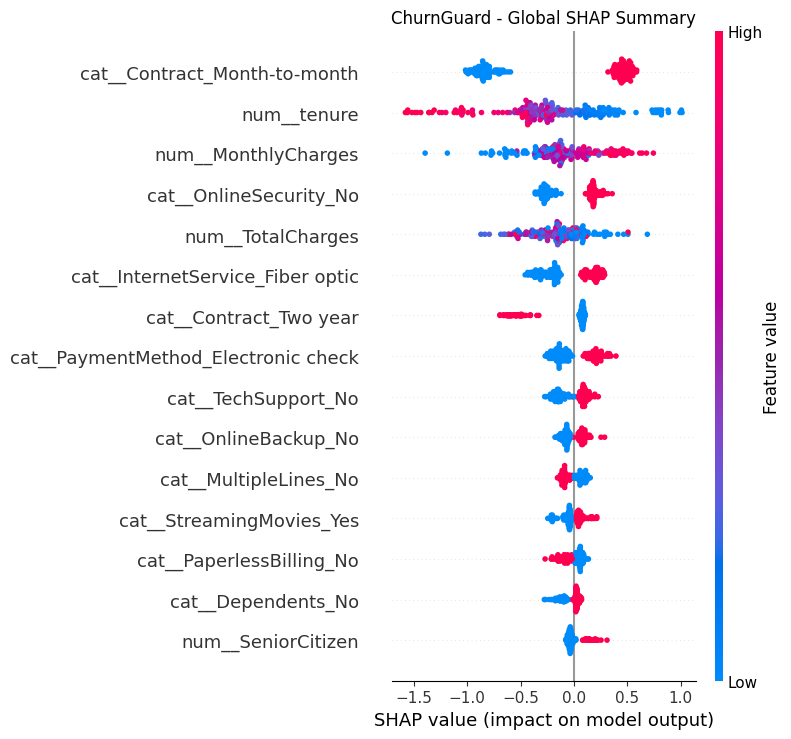

Global SHAP plot saved successfully!


In [ ]:

import shap
import matplotlib.pyplot as plt

# Fitted XGBoost pipeline from calibrated model
fitted_pipeline = model.calibrated_classifiers_[0].estimator
preprocessor = fitted_pipeline.named_steps["preprocessor"]
xgb_model = fitted_pipeline.named_steps["classifier"]

# Use a sample of validation customers
X_sample = X_val.sample(
    n=min(200, len(X_val)),
    random_state=42
)

X_transformed = preprocessor.transform(X_sample)
feature_names = preprocessor.get_feature_names_out()

# Calculate SHAP values
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_transformed)

# Global summary plot
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title("ChurnGuard - Global SHAP Summary")
plt.tight_layout()
plt.savefig(
    "/content/churnguard_shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Global SHAP plot saved successfully!")


In [ ]:

from google.colab import files

files.download("/content/churnguard_shap_summary.png")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import numpy as np

# Validation customers ki churn probabilities
val_probs = model.predict_proba(X_val)[:, 1]

# Current threshold par high-risk/targeted customers
predicted_churn = val_probs >= threshold

# Actual churners among targeted customers
actual_churn = np.asarray(y_val) == 1
caught_churners = int((predicted_churn & actual_churn).sum())
targeted_customers = int(predicted_churn.sum())

# Business assumptions — apne actual figures milne par update karna
CUSTOMER_VALUE = 5000
RETENTION_SUCCESS_RATE = 0.30
OFFER_COST = 500

expected_retained = caught_churners * RETENTION_SUCCESS_RATE
expected_value_saved = expected_retained * CUSTOMER_VALUE
total_offer_cost = targeted_customers * OFFER_COST
net_estimated_impact = expected_value_saved - total_offer_cost

report = pd.DataFrame([{
    "Threshold": threshold,
    "Customers_Targeted": targeted_customers,
    "Churners_Identified": caught_churners,
    "Assumed_Retention_Success_Rate": RETENTION_SUCCESS_RATE,
    "Expected_Customers_Retained": round(expected_retained, 1),
    "Expected_Value_Saved": round(expected_value_saved, 2),
    "Estimated_Offer_Cost": round(total_offer_cost, 2),
    "Estimated_Net_Impact": round(net_estimated_impact, 2)
}])

display(report)
report.to_csv("/content/churnguard_business_impact.csv", index=False)

print("Business impact report saved!")


,Threshold,Customers_Targeted,Churners_Identified,Assumed_Retention_Success_Rate,Expected_Customers_Retained,Expected_Value_Saved,Estimated_Offer_Cost,Estimated_Net_Impact
0,0.1,820,345,0.3,103.5,517500.0,410000,107500.0


Business impact report saved!


In [ ]:

print("Threshold:", threshold)
print("Customers targeted:", targeted_customers)
print("Churners identified:", caught_churners)
print("Expected customers retained:", round(expected_retained, 1))
print("Expected value saved:", round(expected_value_saved, 2))
print("Estimated offer cost:", round(total_offer_cost, 2))
print("Estimated net impact:", round(net_estimated_impact, 2))


Threshold: 0.1
Customers targeted: 820
Churners identified: 345
Expected customers retained: 103.5
Expected value saved: 517500.0
Estimated offer cost: 410000
Estimated net impact: 107500.0


In [ ]:

print("Demo exists:", "demo" in globals())
print("Model exists:", "model" in globals())
print("Feature columns exist:", "feature_columns" in globals())
print("SHAP explainer exists:", "explainer" in globals())


Demo exists: True
Model exists: True
Feature columns exist: True
SHAP explainer exists: True


In [ ]:

import gradio as gr
import pandas as pd
import numpy as np

def predict_csv(file):
    if file is None:
        return None, "Please upload a CSV file."

    try:
        data = pd.read_csv(file.name if hasattr(file, "name") else file)

        # Dataset se extra columns remove karo
        data = data.drop(
            columns=["customerID", "Churn", "TenureGroup"],
            errors="ignore"
        )

        # Required features check karo
        missing = [col for col in feature_columns if col not in data.columns]
        if missing:
            return None, "CSV mein required columns missing hain: " + ", ".join(missing)

        # Model ke expected feature order mein columns rakho
        data = data[feature_columns].copy()

        # Numeric columns ko numbers mein convert karo
        for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
            data[col] = pd.to_numeric(data[col], errors="coerce")

        # Empty numeric values ko median se fill karo
        for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
            data[col] = data[col].fillna(X[col].median())

        probabilities = model.predict_proba(data)[:, 1]
        predictions = (probabilities >= threshold).astype(int)

        results = data.copy()
        results["Churn_Probability"] = np.round(probabilities, 4)
        results["Prediction"] = np.where(
            predictions == 1, "Likely to Churn", "Likely to Stay"
        )
        results["Risk_Level"] = np.where(
            probabilities >= 0.60, "High",
            np.where(predictions == 1, "Medium", "Low")
        )

        return results, f"Done! {len(results)} customers processed."

    except Exception as e:
        return None, f"Error: {str(e)}"


csv_demo = gr.Interface(
    fn=predict_csv,
    inputs=gr.File(label="Upload Customer CSV", file_types=[".csv"], type="filepath"),
    outputs=[
        gr.Dataframe(label="Customer Churn Predictions"),
        gr.Textbox(label="Status")
    ],
    title="ChurnGuard — CSV Batch Prediction",
    description="Upload a CSV containing the same customer feature columns used by the model."
)

print("CSV Upload interface created successfully!")


CSV Upload interface created successfully!


In [ ]:

import gradio as gr

combined_demo = gr.TabbedInterface(
    [demo, csv_demo],
    ["Single Customer Prediction", "CSV Batch Upload"],
    title="ChurnGuard — Customer Churn Prediction & Retention Tool"
)

print("Both interfaces combined successfully!")


Both interfaces combined successfully!


In [ ]:

combined_demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://560d625ff593299c26.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
